In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "train.csv"
OPTIONS = list("ABCDE")
pd.set_option("display.max_colwidth", 160)

df = pd.read_csv(DATA_PATH)
display(df.head())

,id,prompt,A,B,C,D,E,answer
0,0,"Which of the following statements accurately describes the impact of Modified Newtonian Dynamics (MOND) on the observed ""missing baryonic mass"" discrepancy ...","MOND is a theory that reduces the observed missing baryonic mass in galaxy clusters by postulating the existence of a new form of matter called ""fuzzy dark ...",MOND is a theory that increases the discrepancy between the observed missing baryonic mass in galaxy clusters and the measured velocity dispersions from a f...,MOND is a theory that explains the missing baryonic mass in galaxy clusters that was previously considered dark matter by demonstrating that the mass is in ...,MOND is a theory that reduces the discrepancy between the observed missing baryonic mass in galaxy clusters and the measured velocity dispersions from a fac...,MOND is a theory that eliminates the observed missing baryonic mass in galaxy clusters by imposing a new mathematical formulation of gravity that does not r...,D
1,1,Which of the following is an accurate definition of dynamic scaling in self-similar systems?,"Dynamic scaling refers to the evolution of self-similar systems, where data obtained from snapshots at fixed times exhibits similarity to the respective dat...","Dynamic scaling refers to the non-evolution of self-similar systems, where data obtained from snapshots at fixed times is similar to the respective data tak...","Dynamic scaling refers to the evolution of self-similar systems, where data obtained from snapshots at fixed times is dissimilar to the respective data take...","Dynamic scaling refers to the non-evolution of self-similar systems, where data obtained from snapshots at fixed times is dissimilar to the respective data ...","Dynamic scaling refers to the evolution of self-similar systems, where data obtained from snapshots at fixed times is independent of the respective data tak...",A
2,2,Which of the following statements accurately describes the origin and significance of the triskeles symbol?,"The triskeles symbol was reconstructed as a feminine divine triad by the rulers of Syracuse, and later adopted as an emblem. Its usage may also be related t...","The triskeles symbol is a representation of three interlinked spirals, which was adopted as an emblem by the rulers of Syracuse. Its usage in modern flags o...","The triskeles symbol is a representation of a triple goddess, reconstructed by the rulers of Syracuse, who adopted it as an emblem. Its significance lies in...","The triskeles symbol represents three interlocked spiral arms, which became an emblem for the rulers of Syracuse. Its usage in modern flags of Sicily is due...","The triskeles symbol is a representation of the Greek goddess Hecate, reconstructed by the rulers of Syracuse. Its adoption as an emblem was due to its cult...",A
3,3,What is the significance of regularization in terms of renormalization problems in physics?,"Regularizing the mass-energy of an electron with a finite radius can theoretically simplify calculations involving infinities or singularities, thereby prov...",Regularizing the mass-energy of an electron with an infinite radius allows for the breakdown of a theory that is valid under one set of conditions. This app...,Regularizing the mass-energy of an electron with a finite radius is a means of demonstrating that a system below a certain size can be explained without the...,Regularizing the mass-energy of an electron with an infinite radius can be used to provide a highly accurate description of a system under specific conditio...,Regularizing the mass-energy of an electron with an infinite radius is essential for explaining how a system below a certain size operates. This approach ca...,C
4,4,Which of the following statements accurately describes the relationship between the dimensions of a diffracting object and the angular spacing of features i...,"The angular spacing of features in the diffraction pattern is indirectly proportional to the dimensio

## 1. Посмотрим на вопросы

In [3]:
for _, row in df.sample(n=min(5, len(df)), random_state=42).iterrows():
    print("Вопрос:", row["prompt"])
    for option in OPTIONS:
        print(f"{option}: {row[option]}")
    print("Правильный ответ:", row["answer"], "\n")

Вопрос: What is the main sequence in astronomy?
A: The main sequence is a type of galaxy that contains a large number of stars.
B: The main sequence is a type of black hole that is formed from the collapse of a massive star.
C: The main sequence is a continuous and distinctive band of stars that appears on plots of stellar color versus brightness. Stars on this band are known as main-sequence stars or dwarf stars.
D: The main sequence is a group of planets that orbit around a star in a solar system.
E: The main sequence is a type of nebula that is formed from the explosion of a supernova.
Правильный ответ: C 

Вопрос: What is the "ultraviolet catastrophe"?
A: It is a phenomenon that occurs only in multi-mode vibration.
B: It is the misbehavior of a formula for higher frequencies.
C: It is the standing wave of a string in harmonic resonance.
D: It is a flaw in classical physics that results in the misallocation of energy.
E: It is a disproven theory about the distribution of electromagn

## 2. Качество данных

In [9]:
summary = pd.DataFrame({
    "тип": df.dtypes.astype(str),
    "пропуски": df.isna().sum(),
    "пустые строки": df.apply(
        lambda col: col.astype("string").str.strip().eq("").sum()
    ),
})
display(summary)
invalid = ~df["answer"].isin(OPTIONS)
print("Недопустимых меток:", int(invalid.sum()))
display(df.loc[invalid])

normalized_prompt = df["prompt"].astype("string").str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
repeated = normalized_prompt.duplicated(keep=False) & normalized_prompt.notna()
print("Полных повторов вопроса, вариантов и метки:", int(df.duplicated().sum()))
print("Строк с повторяющимся текстом вопроса:", int(repeated.sum()))
display(df.loc[repeated])

,тип,пропуски,пустые строки
id,int64,0,0
prompt,str,0,0
A,str,0,0
B,str,0,0
C,str,0,0
D,str,0,0
E,str,0,0
answer,str,0,0


Недопустимых меток: 0


,id,prompt,A,B,C,D,E,answer


Полных повторов вопроса, вариантов и метки: 0
Строк с повторяющимся текстом вопроса: 0


,id,prompt,A,B,C,D,E,answer


## 3. Распределение правильных ответов

,количество,доля
answer,,
A,37,0.185
B,48,0.240
C,44,0.220
D,38,0.190
E,33,0.165


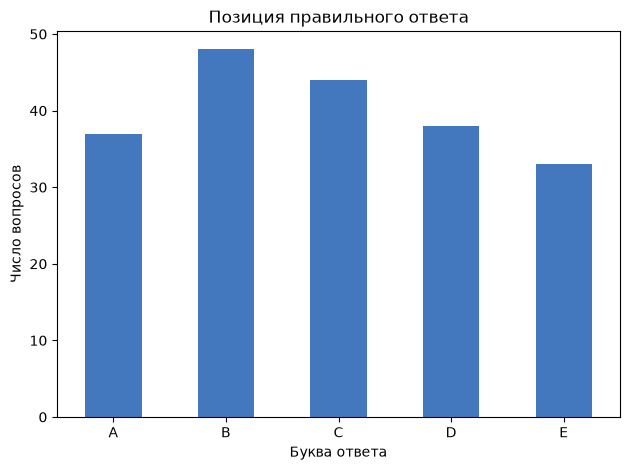

In [10]:
counts = df["answer"].value_counts().reindex(OPTIONS, fill_value=0)
display(pd.DataFrame({"количество": counts, "доля": counts / len(df)}))
counts.plot.bar(rot=0, color="#4378bf", title="Позиция правильного ответа")
plt.xlabel("Буква ответа")
plt.ylabel("Число вопросов")
plt.tight_layout()
plt.show()

## 4. Длина текстов

,prompt,A,B,C,D,E
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,11.360000,25.965000,26.205000,26.300000,25.765000,25.950000
std,6.321408,16.994051,18.144118,16.989799,16.854082,17.449352
min,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,6.000000,13.000000,12.750000,14.000000,14.000000,13.000000
50%,10.000000,22.000000,23.000000,24.000000,22.000000,22.500000
75%,14.000000,37.000000,36.000000,36.000000,36.250000,36.250000
max,42.000000,81.000000,118.000000,82.000000,78.000000,105.000000


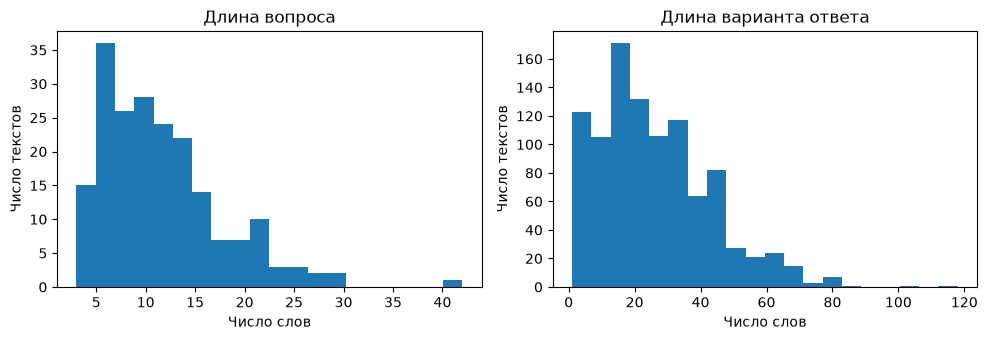

,id,prompt,A,B,C,D,E,answer
12,12,What is one of the examples of the models proposed by cosmologists and theoretical physicists without the cosmological or Copernican principles that can be ...,"The Copernican principle, which proposes that Earth, the Solar System, and the Milky Way are not at the centre of the universe, but instead, the universe is...","Inhomogeneous cosmology, which states that the universe is entirely homogeneous and isotropic, directly proportional to the density of matter and radiation....","Inhomogeneous cosmology, which models the universe as an extremely large, low-density void, instead of using the concept of dark energy. According to the mo...","The cosmological principle, which proposes that Earth, the Solar System, and the Milky Way are at the centre of the universe. This principle is a modificati...","The principle of dark energy, which proposes that a new form of energy, not previously detected, is responsible for the acceleration of the expansion of the...",C
61,61,What is the reason that it is nearly impossible to see light emitted at the Lyman-alpha transition wavelength from a star farther than a few hundred light y...,"Far ultraviolet light is absorbed effectively by the charged components of the ISM, including atomic helium, which has a typical absorption wavelength of ab...","Far ultraviolet light is absorbed effectively by the neutral components of the ISM, including atomic hydrogen, which has a typical absorption wavelength of ...","Far ultraviolet light is absorbed effectively by the charged components of the ISM, including atomic hydrogen, which has a typical absorption wavelength of ...","Far ultraviolet light is absorbed effectively by the neutral components of the ISM, including atomic helium, which has a typical absorption wavelength of ab...","Far ultraviolet light is absorbed effectively by the neutral components of the ISM, including atomic hydrogen, which has a typical absorption wavelength of ...",B
60,60,What is the revised view of the atmosphere's nature based on the time-varying multistability that is associated with the modulation of large-scale processes...,The atmosphere is a system that is only influenced by large-scale processes and does not exhibit any small-scale feedback.,"The atmosphere possesses both chaos and order, including emerging organized systems and time-varying forcing from recurrent seasons.",The atmosphere is a system that is only influenced by small-scale processes and does not exhibit any large-scale modulation.,The atmosphere is a completely chaotic system with no order or organization.,The atmosphere is a completely ordered system with no chaos or randomness.,B


In [12]:
lengths = df[["prompt", *OPTIONS]].apply(lambda col: col.astype("string").str.split().str.len())
display(lengths.describe())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
lengths["prompt"].plot.hist(bins=20, ax=axes[0], title="Длина вопроса")
lengths[OPTIONS].stack().plot.hist(bins=20, ax=axes[1], title="Длина варианта ответа")
for ax in axes:
    ax.set_xlabel("Число слов")
    ax.set_ylabel("Число текстов")
plt.tight_layout()
plt.show()
display(df.loc[lengths["prompt"].nlargest(3).index])
